# 00 - Khảo sát PlantVillage

Notebook này ghi nhận kích thước dữ liệu, phân bố lớp, ảnh mẫu và các kiểm tra chất lượng trước khi chia dữ liệu.

In [1]:
!pip install metadata
!pip install matplotlib
!pip install seaborn

  Using cached metadata-0.2.tar.gz (1.5 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached metadata-0.1.1.tar.gz (1.5 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
INFO: pip is looking at multiple versions of metadata to determine which version is compatible with other requirements. This could take a while.
  Using cached metadata-0.1.tar.gz (1.1 kB)
  Installing build dependencies: started
  Installing build d

ERROR: Cannot install metadata==0.1, metadata==0.1.1 and metadata==0.2 because these package versions have conflicting dependencies.
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import discover_images

DATA_ROOT = PROJECT_ROOT.parent / 'PlantVillage-Dataset-master' / 'PlantVillage-Dataset-master' / 'raw' / 'color'
metadata = discover_images(DATA_ROOT)
print(f'{len(metadata):,} ảnh, {metadata.class_name.nunique()} lớp')
metadata.head()

ModuleNotFoundError: No module named 'seaborn'

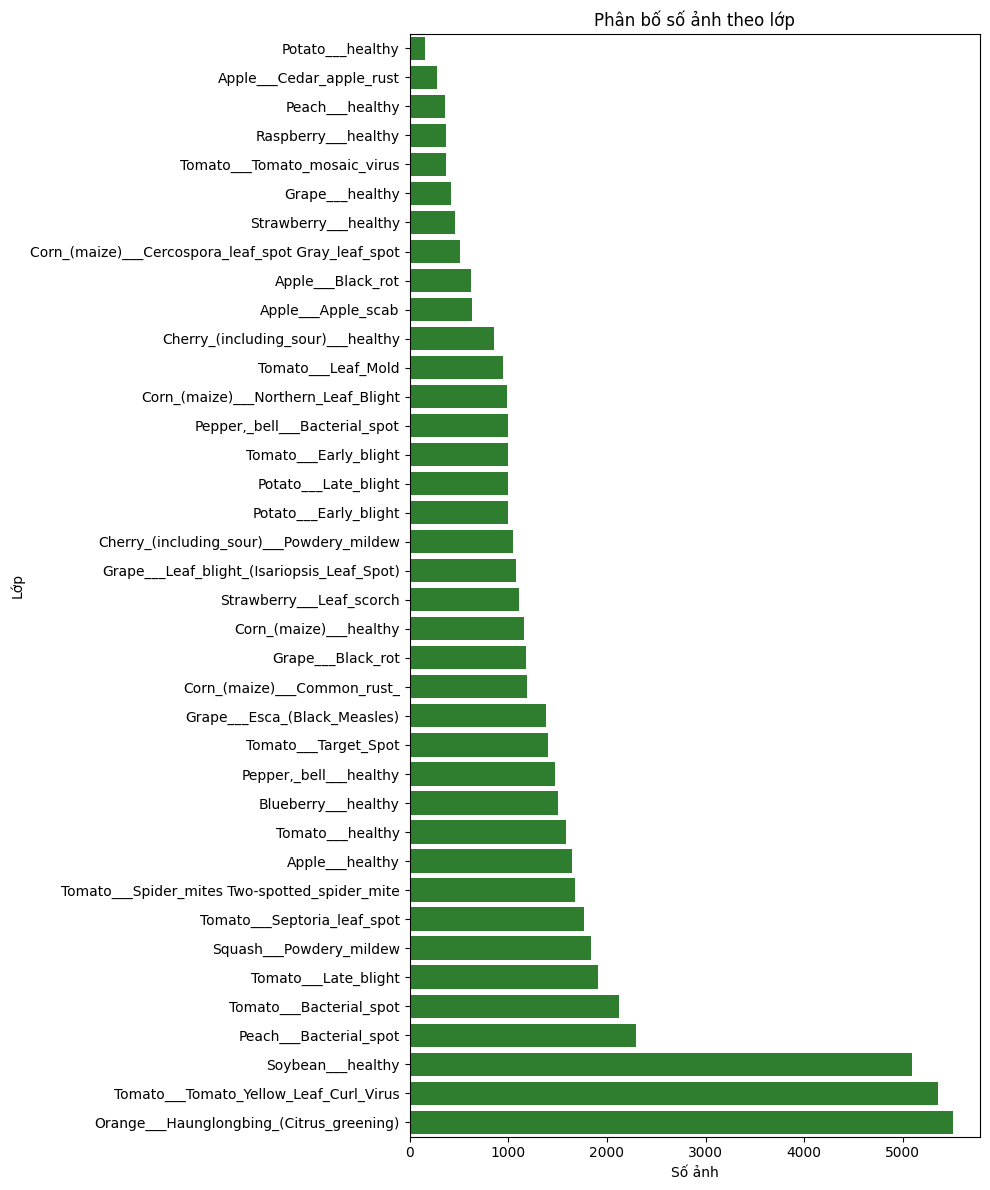

In [2]:
counts = metadata['class_name'].value_counts().sort_values()
plt.figure(figsize=(10, 12))
sns.barplot(x=counts.values, y=counts.index, color='forestgreen')
plt.title('Phân bố số ảnh theo lớp')
plt.xlabel('Số ảnh'); plt.ylabel('Lớp')
plt.tight_layout()
plt.show()

In [ ]:
# Phan tich chi tiet theo loai cay va trang thai suc khoe
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import discover_images

DATA_ROOT = PROJECT_ROOT.parent / 'PlantVillage-Dataset-master' / 'PlantVillage-Dataset-master' / 'raw' / 'color'
metadata = discover_images(DATA_ROOT)

analysis = metadata.copy()
analysis[['plant', 'condition']] = analysis['class_name'].str.split('___', n=1, expand=True)
analysis['health_status'] = analysis['condition'].str.lower().eq('healthy').map({True: 'Khoe', False: 'Benh'})

summary = pd.DataFrame({
    'Chi so': [
        'Tong so anh', 'Tong so loai cay', 'Tong so lop phan loai',
        'So loai cay co anh khoe', 'So loai cay co anh benh',
        'So lop khoe', 'So lop benh',
    ],
    'Gia tri': [
        len(analysis),
        analysis['plant'].nunique(),
        analysis['class_name'].nunique(),
        analysis.loc[analysis['health_status'].eq('Khoe'), 'plant'].nunique(),
        analysis.loc[analysis['health_status'].eq('Benh'), 'plant'].nunique(),
        analysis.loc[analysis['health_status'].eq('Khoe'), 'class_name'].nunique(),
        analysis.loc[analysis['health_status'].eq('Benh'), 'class_name'].nunique(),
    ],
})
print('TONG QUAN DATASET')
display(summary)

class_counts = (
    analysis.groupby(['plant', 'health_status'])['class_name'].nunique()
    .unstack(fill_value=0)
    .reindex(columns=['Khoe', 'Benh'], fill_value=0)
)
image_counts = (
    analysis.groupby(['plant', 'health_status']).size()
    .unstack(fill_value=0)
    .reindex(columns=['Khoe', 'Benh'], fill_value=0)
)

plant_summary = pd.DataFrame({
    'so_lop_khoe': class_counts['Khoe'],
    'so_lop_benh': class_counts['Benh'],
    'so_anh_khoe': image_counts['Khoe'],
    'so_anh_benh': image_counts['Benh'],
})
plant_summary['tong_so_anh'] = plant_summary['so_anh_khoe'] + plant_summary['so_anh_benh']
plant_summary = plant_summary.sort_values('tong_so_anh', ascending=False)

print('CHI TIET THEO TUNG LOAI CAY')
display(plant_summary)

class_detail = (
    analysis.groupby(['plant', 'health_status'])['condition']
    .agg(lambda values: ', '.join(sorted(values.unique())))
    .unstack(fill_value='Khong co')
    .rename(columns={'Khoe': 'cac_lop_khoe', 'Benh': 'cac_lop_benh'})
)
display(class_detail)

plot_data = plant_summary[['so_anh_khoe', 'so_anh_benh']].rename(
    columns={'so_anh_khoe': 'Khoe', 'so_anh_benh': 'Benh'}
)
plot_data.plot(kind='bar', stacked=True, figsize=(15, 6), color=['#66c2a5', '#fc8d62'])
plt.title('So luong anh khoe va benh theo tung loai cay')
plt.xlabel('Loai cay')
plt.ylabel('So anh')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Trang thai')
plt.tight_layout()
plt.show()
